In [1]:
import matplotlib.pyplot as plt
import xarray as xr
from pathlib import Path

%cd /g/data/w42/dr6273/work/wind_drought/
import src.wind as wind

/g/data/w42/dr6273/work/wind_drought


In [2]:
%load_ext autoreload
%autoreload 2

### Wind data

In [3]:
def load_wind(dataset, variable, region, scenario=None, averaging="equal"):
    """ Return da of wind speed data for given criteria """
    wind_path = "/g/data/ng72/dr6273/work/projects/wind_drought/data/"+dataset+"/power_grid/"
    directory_path = Path(wind_path)

    # Filter by variable
    matching_files = [f.name for f in directory_path.iterdir() if f.is_file() and variable in f.name]

    # Filter by region
    matching_files = [f for f in matching_files if region in f]

    # Filter by scenario
    if scenario is not None:
        matching_files = [f for f in matching_files if scenario in f]

    # Filter by averaging method
    matching_files = [f for f in matching_files if averaging in f]
    
    if len(matching_files) > 1:
        raise ValueError("Need to filter more files")
        
    return xr.open_dataset(wind_path + matching_files[0])

In [4]:
# REGIONS = ["NEM-SC30", "SE-SC30", "SWIS", "NWIS"]

In [5]:
obs_dict = {}
for dataset in ["ERA5", "BARRA-R2"]:
    obs_dict[dataset] = {}

    for variable in ["wind_speed", "capacity_factor"]:
        obs_dict[dataset][variable] = {}

        for region in ["NEM", "SE", "SWIS", "NWIS"]:
            
            if region in ["NEM", "SE"]:
                for scenario in ["SC30", "SC40", "SC50"]:
                    obs_dict[dataset][variable][region+"-"+scenario] = {}

                    for averaging in ["equal", "weighted"]:
                        da = load_wind(dataset, variable, region, scenario, averaging)
                        obs_dict[dataset][variable][region+"-"+scenario][averaging] = da[variable]

            else:
                da = load_wind(dataset, variable, region)
                obs_dict[dataset][variable][region] = da[variable]

In [98]:
def plot_seasonal_cycle(ax, da_dict, region, variable, reducer="mean"):
    """
    Plot seasonal cycle, either mean, or quantile
    
    reducer: 'mean' or float between 0.0 and 1.0
    """
    for marker, dataset in zip(["o", None] , ["ERA5", "BARRA-R2"]):
        # for variable in ["wind_speed"]:
            # for region in ["NEM", "SE", "SWIS", "NWIS"][:1]:
        if region in ["NEM", "SE"]:
            for colour, scenario in zip(
                ["#648FFF", "#DC267F", "#FFB000"], ["SC30", "SC40", "SC50"]
            ):
                for ls, averaging in zip(["-", "--"], ["equal", "weighted"]):
                    da = obs_dict[dataset][variable][region+"-"+scenario][averaging]
                    label = dataset + ", " + region + "-" + scenario + ", " + averaging

                    if reducer == "mean":
                        da_reduced = da.groupby("time.month").mean()
                    elif isinstance(reducer, float) and 0.0 <= reducer <= 1.0:
                        da_reduced = da.groupby("time.month").quantile(reducer, "time")
                    else:
                        raise ValueError("Incorrect 'reducer'")
                        
                    da_reduced.plot(
                        ax=ax,
                        marker=marker,
                        ls=ls,
                        label=label,
                        color=colour
                    )

        else:
            da = obs_dict[dataset][variable][region]
            label = dataset + ", " + region

            if reducer == "mean":
                da_reduced = da.groupby("time.month").mean()
            elif isinstance(reducer, float) and 0.0 <= reducer <= 1.0:
                da_reduced = da.groupby("time.month").quantile(reducer, "time")
            else:
                raise ValueError("Incorrect 'reducer'")
                        
            da_reduced.plot(
                ax=ax,
                marker=marker,
                ls="-",
                label=label,
                color="#648FFF"
            )
    ax.legend(ncol=1)

    if variable == "capacity_factor":
        ax.set_ylabel("Capacity factor [-]")

    if reducer == "mean":
        reducer_name = "mean"
    else: #isinstance(reducer, float) and 0.0 <= reducer <= 1.0:
        reducer_name = str(int(reducer * 100)) + "th pctl"

    ax.set_title(region + " " + reducer_name + " " + variable.replace("_", " "), fontsize=10, loc="center")

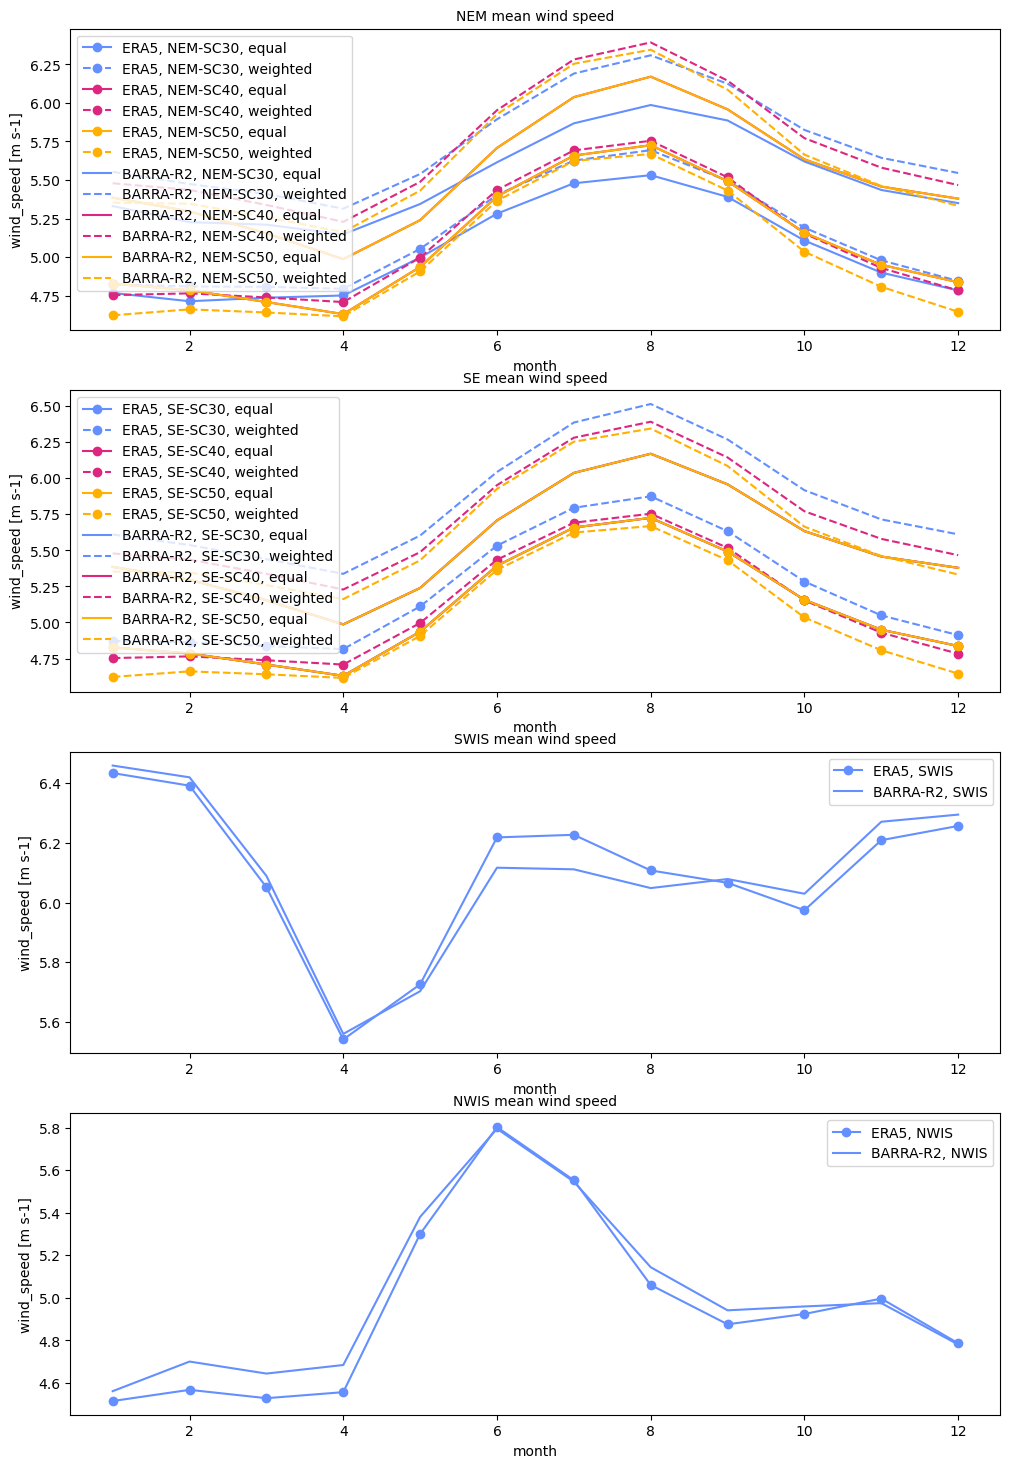

In [94]:
fig, ax = plt.subplots(4, 1, figsize=(12,18))

plot_seasonal_cycle(ax[0], obs_dict, "NEM", "wind_speed")
plot_seasonal_cycle(ax[1], obs_dict, "SE", "wind_speed")
plot_seasonal_cycle(ax[2], obs_dict, "SWIS", "wind_speed")
plot_seasonal_cycle(ax[3], obs_dict, "NWIS", "wind_speed")

plt.savefig("figures/seasonal_cycle_mean_wind_speed.png", dpi=300)
# plt.close(fig)

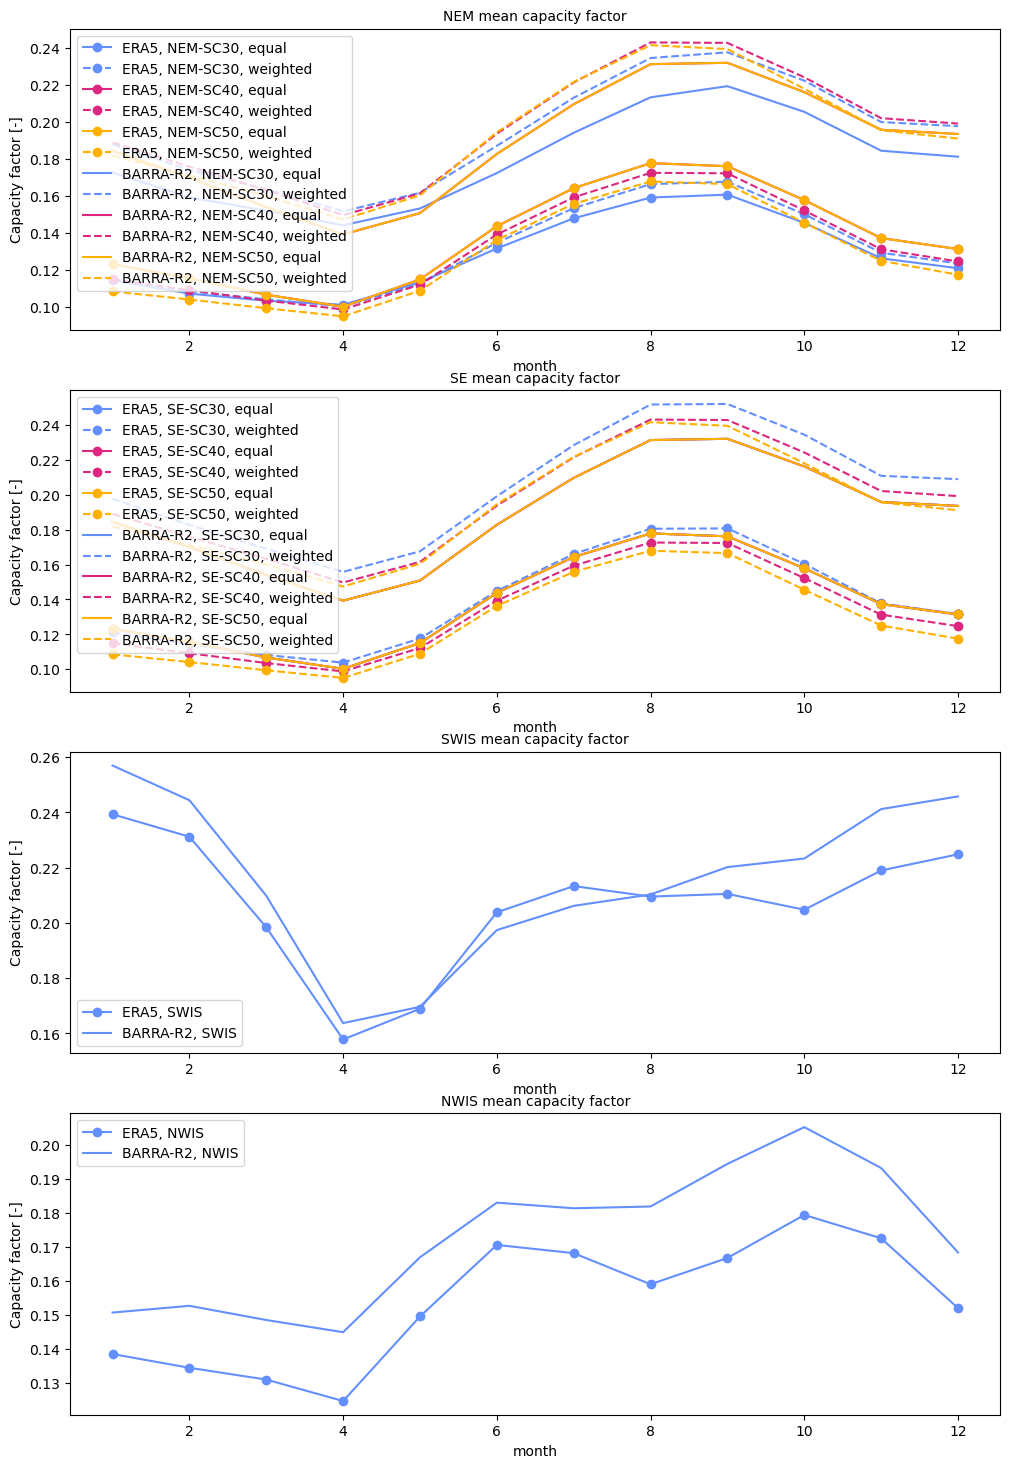

In [95]:
fig, ax = plt.subplots(4, 1, figsize=(12,18))

plot_seasonal_cycle(ax[0], obs_dict, "NEM", "capacity_factor")
plot_seasonal_cycle(ax[1], obs_dict, "SE", "capacity_factor")
plot_seasonal_cycle(ax[2], obs_dict, "SWIS", "capacity_factor")
plot_seasonal_cycle(ax[3], obs_dict, "NWIS", "capacity_factor")

plt.savefig("figures/seasonal_cycle_mean_capacity_factor.png", dpi=300)
# plt.close(fig)

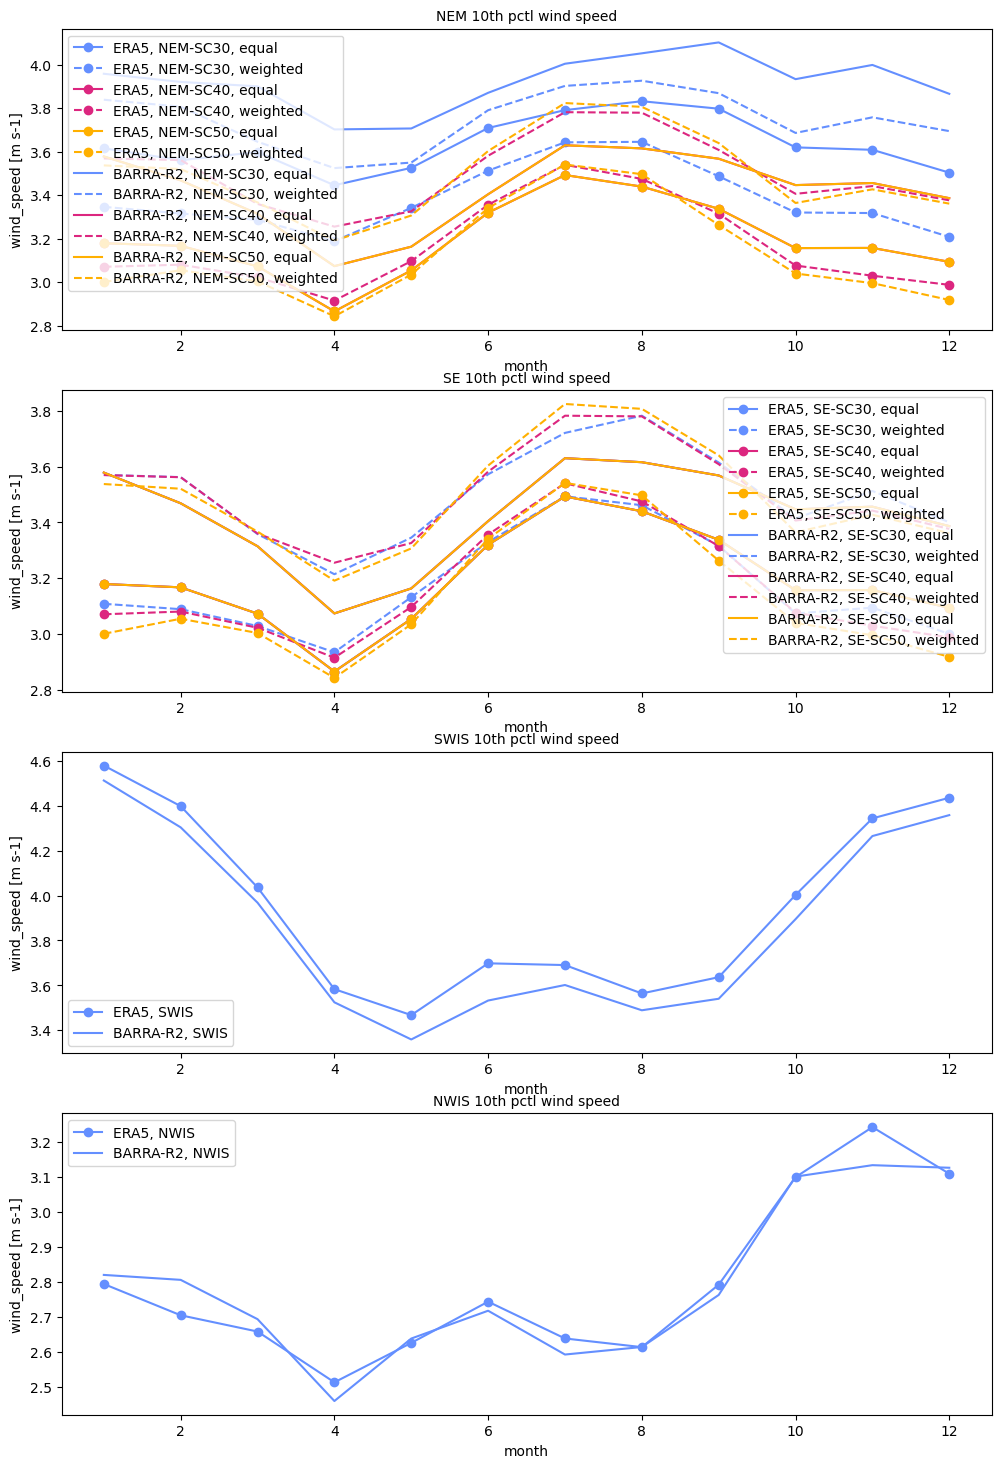

In [99]:
fig, ax = plt.subplots(4, 1, figsize=(12,18))

plot_seasonal_cycle(ax[0], obs_dict, "NEM", "wind_speed", reducer=0.1)
plot_seasonal_cycle(ax[1], obs_dict, "SE", "wind_speed", reducer=0.1)
plot_seasonal_cycle(ax[2], obs_dict, "SWIS", "wind_speed", reducer=0.1)
plot_seasonal_cycle(ax[3], obs_dict, "NWIS", "wind_speed", reducer=0.1)

plt.savefig("figures/seasonal_cycle_10pctl_wind_speed.png", dpi=300)
# plt.close(fig)

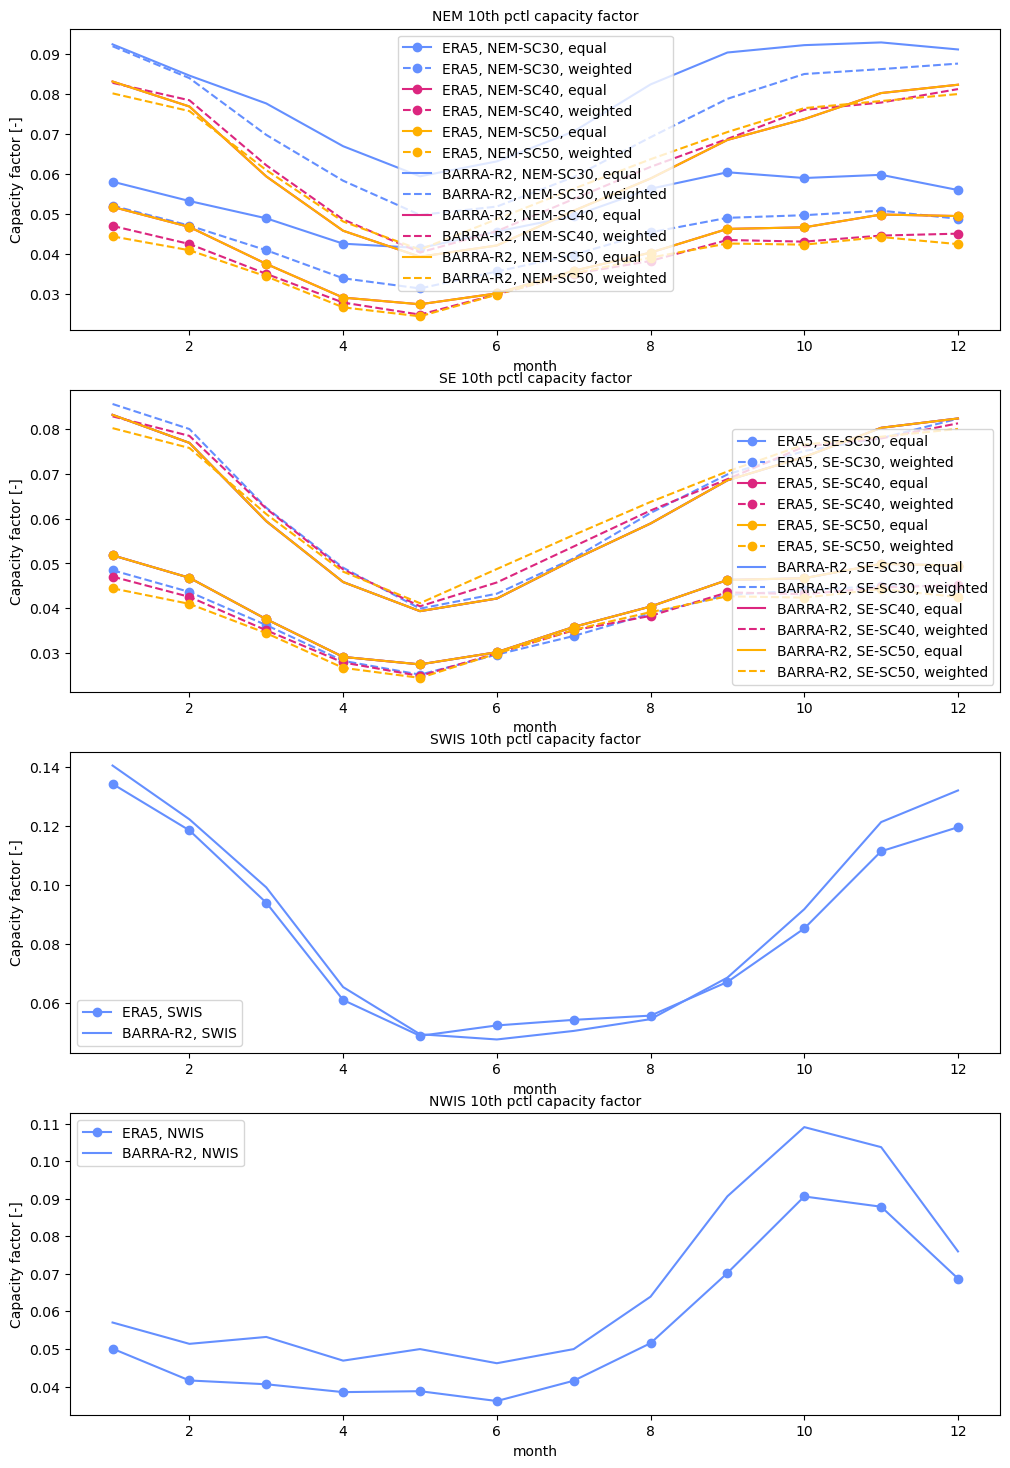

In [100]:
fig, ax = plt.subplots(4, 1, figsize=(12,18))

plot_seasonal_cycle(ax[0], obs_dict, "NEM", "capacity_factor", reducer=0.1)
plot_seasonal_cycle(ax[1], obs_dict, "SE", "capacity_factor", reducer=0.1)
plot_seasonal_cycle(ax[2], obs_dict, "SWIS", "capacity_factor", reducer=0.1)
plot_seasonal_cycle(ax[3], obs_dict, "NWIS", "capacity_factor", reducer=0.1)

plt.savefig("figures/seasonal_cycle_10pctl_capacity_factor.png", dpi=300)
# plt.close(fig)

### Wind statistics

In [10]:
def plot_ws_hist(ax, da, region):
    """ Histogram of wind speed """
    bins = np.arange(0, 9.5, 0.5)
    ax.hist(da, bins=bins, density=True, rwidth=0.9, label=region, color='tab:blue', alpha=0.5)
    
    pctl10 = np.percentile(da, 10)
    print(pctl10)
    ax.axvline(pctl10, color='tab:blue', label='10th percentile')
    
    ax.set_xlabel('daily average surface wind speed [m/s]')
    ax.set_ylabel('Probability density [s/m]')
    ax.set_title('BARRA-R2 ' + region, fontsize=10)
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 0.6)
    ax.legend()

2.8578365490351456
2.424089104089355
2.599731585630801
2.788453555714856


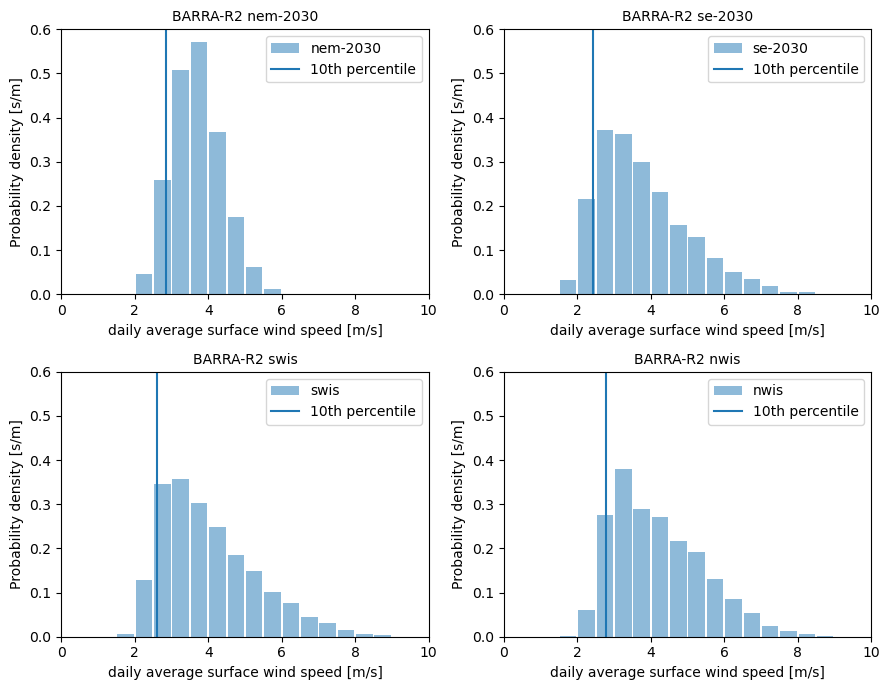

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(9,7))
for i, (r, da) in enumerate(obs_dict.items()):
    ax = axes.flatten()[i]
    plot_ws_hist(ax, da['sfcWind'], r)
plt.tight_layout()

In [ ]:
def plot_ws_ts(ax, da, region):
    """ Plot wind speed time series """
    time = pd.DatetimeIndex(da.time.values)
    x = np.arange(da.size)

    # annual = da.resample(time="3MS").mean()
    # x_ann = np.arange(annual.size)
    # print(annual)

    ax.plot(x, da.values, label=region, color='tab:blue', alpha=1)
    # ax.plot(x_ann, annual.values, color="tab:orange")

    # Annual mean for each year
    annual_mean = da.groupby("time.year").mean()

    # Repeat each annual mean for all observations in that year
    annual_mean_ts = xr.concat(
        [
            xr.full_like(da.sel(time=da.time.dt.year == year), mean)
            for year, mean in zip(annual_mean.year.values, annual_mean.values)
        ],
        dim="time"
    )

    ax.plot(
        x, annual_mean_ts.values,
        color="tab:orange",
        linewidth=2,
        label="Annual mean"
    )

    # Tick only at 1 May each year
    may_starts = np.flatnonzero((time.month == 5) & (time.day == 1))
    ax.set_xticks(may_starts[::5])
    ax.set_xticklabels(time[may_starts[::5]].year, rotation=30)

    ax.set_title('Wind speed ' + region, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('Wind speed [m/s]')
    ax.set_ylim(0,11)

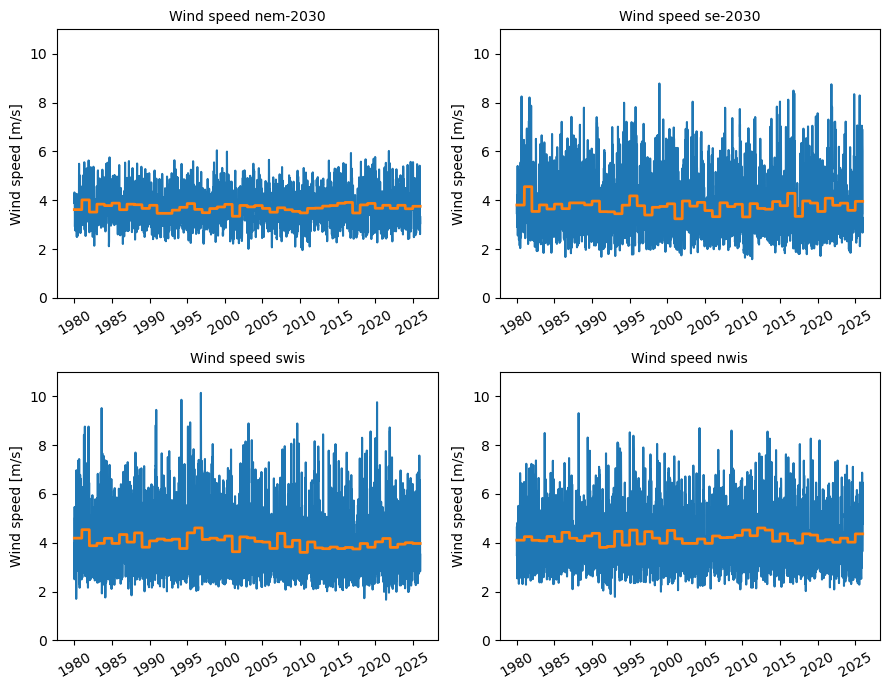

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(9,7))
for i, (r, da) in enumerate(obs_dict.items()):
    ax = axes.flatten()[i]
    plot_ws_ts(ax, da['sfcWind'], r)
plt.tight_layout()

#### Annual maximum wind drought duration (WDDx)

In [11]:
wddx_obs = {}
for r, da in obs_dict.items():
    pctl10 = np.percentile(da['sfcWind'], 10)
    print(pctl10)
    wddx_obs[r] = utils.calc_wddx_obs(da, pctl10)

2.8578365490351456
2.424089104089355
2.599731585630801
2.788453555714856


In [ ]:
def plot_wddx_ts(ax, da, region):
    """ Plot WDDx time series """
    
    da['event_length'].plot(ax=ax, label=region, color='tab:blue', alpha=1)
    ax.set_title('WDDx ' + region, fontsize=10)
    ax.set_xlabel('')
    ax.tick_params(axis="x", labelrotation=30)
    ax.set_ylabel('Event length [d]')
    ax.set_ylim(0,10)

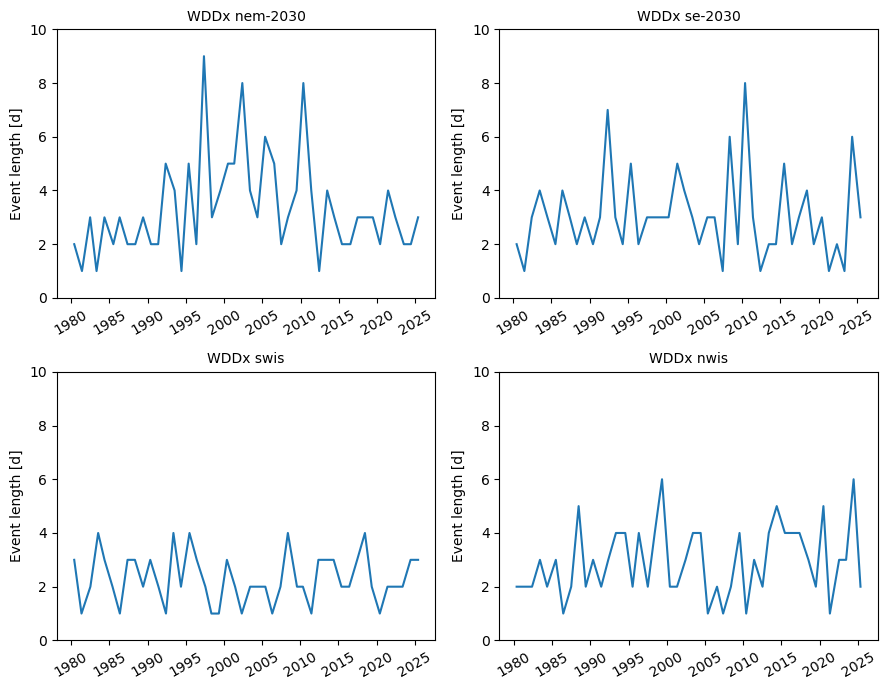

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(9,7))
for i, (r, da) in enumerate(wddx_obs.items()):
    ax = axes.flatten()[i]
    plot_wddx_ts(ax, da, r)
plt.tight_layout()

In [ ]:
def plot_wddx_hist(ax, da, region, density=False):
    """ Histogram of WDDx """
    bins = np.arange(0.5, 16.5, 1)

    ax.hist(
        da['event_length'],
        bins=bins,
        density=density,
        rwidth=0.9,
        label=region,
        color='tab:blue',
        alpha=0.5
    )
    
    if density:
        ylabel = 'Probability density [1/d]'
        ylim = 0.5
        yticks = np.arange(0, 0.6, 0.1)
    else:
        ylabel = 'Event count [-]'
        ylim = 20
        yticks = range(0, 21, 4)
        
    ax.set_xlabel('Annual maximum wind drought duration [d]')
    ax.set_ylabel(ylabel)
    ax.set_title('BARRA-R2 ' + region, fontsize=10)
    ax.set_xlim(0, 10)
    ax.set_ylim(0, ylim)
    ax.set_yticks(yticks)
    ax.legend()

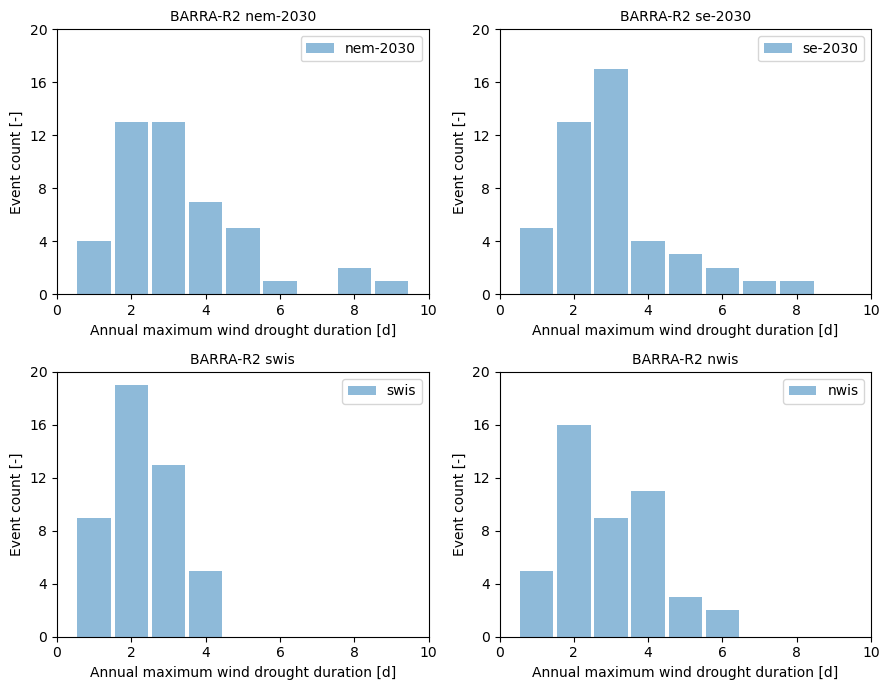

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(9,7))
for i, (r, da) in enumerate(wddx_obs.items()):
    ax = axes.flatten()[i]
    plot_wddx_hist(ax, da, r, density=False)
plt.tight_layout()

#### Longest droughts

In [12]:
def get_droughts(wddx):
    """Return dict of longest wind droughts"""
    droughts_dfs = {}
    for r, da in wddx.items():
        years = da['event_start'].dt.year.values
        df = pd.DataFrame(index=years)
        df['WDDx'] = da['event_length'].values.astype('int32')
        df['start_date'] = pd.to_datetime(da['event_start'].dt.strftime('%Y-%m-%d'))
        df['end_date'] = pd.to_datetime(da['event_start'].dt.strftime('%Y-%m-%d')) + pd.to_timedelta(df['WDDx'] - 1, unit='D')
        droughts_dfs[r] = df.set_index('start_date')
    return droughts_dfs

In [13]:
def get_droughts_subset(droughts, pc_upper, pc_lower):
    """Return dict of droughts longer than pc_upper and between pc_lower and pc_upper"""
    droughts_subset = {}
    for r, df in droughts.items():
        droughts_subset[r] = {}
        
        min_len = pc_upper[r] # minimum length for a 'top drought' is >80th percentile.
        
        top_df = df[df['WDDx'] > min_len].sort_values(['WDDx'], ascending=False)
        
        other_df = df[
            (df['WDDx'] <= min_len) & (df['WDDx'] >= pc_lower[r]) # compare to droughts between 50th and 80th percentiles
            ].sort_values(['WDDx'], ascending=False)
    
        droughts_subset[r]['top'] = top_df
        droughts_subset[r]['other'] = other_df

    return droughts_subset

In [14]:
droughts_dfs = get_droughts(wddx_obs)

In [15]:
droughts_dfs['nem-2030'].sort_values(['WDDx'], ascending=False).head(n=10)

,WDDx,end_date
start_date,,
1997-05-16,9,1997-05-24
2002-05-22,8,2002-05-29
2010-05-14,8,2010-05-21
2005-05-14,6,2005-05-19
1992-05-14,5,1992-05-18
2001-05-01,5,2001-05-05
2000-07-06,5,2000-07-10
2006-07-23,5,2006-07-27
1995-05-17,5,1995-05-21


In [16]:
wddx_p50 = {r: np.percentile(da['event_length'], 50) for r, da in wddx_obs.items()}
wddx_p80 = {r: np.percentile(da['event_length'], 80) for r, da in wddx_obs.items()}

In [17]:
print(wddx_p50)
print(wddx_p80)

{'nem-2030': 3.0, 'se-2030': 3.0, 'swis': 2.0, 'nwis': 3.0}
{'nem-2030': 4.0, 'se-2030': 4.0, 'swis': 3.0, 'nwis': 4.0}


In [18]:
droughts_subset = get_droughts_subset(droughts_dfs, wddx_p80, wddx_p50)

In [19]:
droughts_subset['nem-2030']['top']

,WDDx,end_date
start_date,,
1997-05-16,9,1997-05-24
2002-05-22,8,2002-05-29
2010-05-14,8,2010-05-21
2005-05-14,6,2005-05-19
1992-05-14,5,1992-05-18
1995-05-17,5,1995-05-21
2000-07-06,5,2000-07-10
2001-05-01,5,2001-05-05
2006-07-23,5,2006-07-27


### Synoptic Weather Types

In [20]:
# Australian Synoptic Weather Type data from forked repository
swt = pd.read_csv(
    "../Australian-synoptic-weather-types/SWT_climatology/SWT_climatology.csv",
    index_col=0,
    parse_dates=True
)

In [21]:
ordered_SWTs = [
    "WH-A", "WH-B", "WH-C", "WH-D",
    "CH-A", "CH-B",
    "EH-A", "EH-B", "EH-C", "EH-D", "EH-E",
    "TH-A", "TH-B", "TH-C",
    "FH-A", "FH-B", "FH-C",
    "WCT-A", "WCT-B",
    "COL-A", "COL-B", "COL-C", "COL-D", "COL-E", "COL-F",
    "AM-A", "AM-B", "AM-C", "AM-D", "AM-E"
]

In [22]:
missing_values = set(ordered_SWTs) - set(swt["assigned_SWT"].dropna().unique())

if missing_values:
    print("Missing from swt:", sorted(missing_values))
else:
    print("All ordered_SWTs are present in swt.")

All ordered_SWTs are present in swt.


In [23]:
# Plotting bars for each SWT category in the groups
colors=[
    (134/255,0/255,34/255),(241/255,0/255,241/255),(255/255,134/255,255/255),(255/255,241/255,255/255), #Pink WH
    (255/255,204/255,51/255),(255/255,245/255,204/255), #Yellow CH
    (153/255,15/255,15/255),(178/255,44/255,44/255),(204/255,81/255,81/255),(229/255,126/255,126/255),(255/255,178/255,178/255), #Red EH
    (153/255,84/255,15/255),(204/255,142/255,81/255),(255/255,216/255, 178/255), #Brown TH
    (107/255,153/255,15/255),(163/255,204/255,81/255),(195/255,229/255,126/255), #Green FH (133/255,178/255,44/255),
    (66/255,44/255,178/255),(143/255,126/255,229/255), #Purple WCT
    (5/255,67/255,113/255),(15/255,107/255,153/255),(44/255,133/255,178/255),(81/255,163/255,204/255),(126/255,195/255,229/255),(178/255,229/255,255/255), #Blue COL
    (0/255,60/255,48/255),(1/255,102/255,95/255),(53/255,151/255,143/255),(128/255,205/255,193/255),(199/255,234/255,229/255)
]

In [24]:
colour_by_swt = dict(zip(ordered_SWTs, colors))

Get SWT occurrences during droughts

In [25]:
for a, b in zip(droughts_subset['nem-2030']['top'].index, droughts_subset['nem-2030']['top']['end_date']):
    print(a,b)

1997-05-16 00:00:00 1997-05-24 00:00:00
2002-05-22 00:00:00 2002-05-29 00:00:00
2010-05-14 00:00:00 2010-05-21 00:00:00
2005-05-14 00:00:00 2005-05-19 00:00:00
1992-05-14 00:00:00 1992-05-18 00:00:00
1995-05-17 00:00:00 1995-05-21 00:00:00
2000-07-06 00:00:00 2000-07-10 00:00:00
2001-05-01 00:00:00 2001-05-05 00:00:00
2006-07-23 00:00:00 2006-07-27 00:00:00


In [26]:
swt_distributions = {}
for r, drought_dict in droughts_subset.items():
    swt_distributions[r] = {}

    for drought_type, df in drought_dict.items():
        distributions = {}

        for start, end in zip(df.index, df['end_date']):
            event_swts = swt.loc[start:end, "assigned_SWT"]

            distributions[start] = (
                event_swts
                .value_counts(normalize=False)  # proportions rather than counts
                .reindex(ordered_SWTs, fill_value=0)
            )

        swt_distributions[r][drought_type] = pd.DataFrame(distributions).T

In [27]:
def plot_swt_by_event(ax, region, drought_type='top'):
    """ Plot SWT occurrences for each event """
    from matplotlib.patches import Patch
    import matplotlib.dates as mdates

    events = droughts_subset[region][drought_type]
    for event_number, (start, end) in enumerate(zip(events.index, events['end_date'])):
        event_swts = swt.loc[start:end, "assigned_SWT"]

        bottom = 0

        for event_date, swt_name in event_swts.items():
            ax.bar(
                event_number,
                height=1,
                bottom=bottom,
                width=0.8,
                color=colour_by_swt[swt_name],
                edgecolor="gray",
                linewidth=0.5
            )
    
            bottom += 1

    ax.set_xlabel("Event start date")
    ax.set_ylabel("Event day")

    # Legend
    event_swt_names = set()
    
    for start, row in events.iterrows():
        end = row["end_date"]
    
        event_swt_names.update(
            swt.loc[start:end, "assigned_SWT"]
            .dropna()
            .unique()
        )
    
    legend_handles = [
        Patch(
            facecolor=colour_by_swt[swt_name],
            label=swt_name
        )
        for swt_name in ordered_SWTs
        if swt_name in event_swt_names
    ]
    
    ax.legend(
        handles=legend_handles,
        bbox_to_anchor=(0.51, 1.03),
        loc="upper left",
        # title="SWT",
        ncols=4,
        fontsize=9,
        frameon=True
    )

    # Axis details
    labels = events.index.strftime("%Y-%m-%d")
    ax.set_xticks(range(len(events)))
    ax.set_xticklabels(labels)
    ax.tick_params(axis='x', labelrotation=45)

    ax.set_yticks(np.arange(0.5, 11, 2))
    ax.set_yticklabels(range(1, 12, 2))
    
    min_len = str(events.iloc[-1]['WDDx'])
    ax.set_title('a) ' + region + r' SWT occurrences for each wind drought $\geq $' + min_len + ' days duration', loc='left', fontsize=10)

In [28]:
def plot_swt_hist(ax, distributions, region, show_other=True):
    """ histogram of SWT occurrences during all events """

    top_swt_counts = (
        distributions[region]['top']
        .sum(axis=0)
        .reindex(ordered_SWTs, fill_value=0)
    )
    
    other_swt_counts = (
        distributions[region]['other']
        .sum(axis=0)
        .reindex(ordered_SWTs, fill_value=0)
    )
    
    # climatological counts
    swt_mjj = swt[swt.index.month.isin([5, 6, 7])]
    clim_counts = (
        swt_mjj["assigned_SWT"]
        .value_counts()
        .reindex(ordered_SWTs, fill_value=0)
    )
    
    # Convert to frequencies
    top_event_freq = top_swt_counts / top_swt_counts.sum()
    other_event_freq = other_swt_counts / other_swt_counts.sum()
    clim_freq = clim_counts / clim_counts.sum()
    
    x = range(len(ordered_SWTs))
    
    ax.bar(
        x,
        top_event_freq,
        color=[colour_by_swt[swt] for swt in ordered_SWTs],
        alpha=0.8,
        label="Top events",
    )

    if show_other:
        ax.plot(
            x,
            other_event_freq,
            color="black",
            marker="s",
            ls="--",
            markersize=5,
            linewidth=.8,
            label="Other events",
        )
        
    ax.plot(
        x,
        clim_freq,
        color="black",
        marker="o",
        markersize=5,
        linewidth=.8,
        label="Climatology",
    )
    
    ax.set_xticks(x)
    ax.set_xticklabels(ordered_SWTs, rotation=45, ha="right")
    ax.set_xlabel('SWT')
    ax.set_ylabel("Relative frequency [-]")
    ax.legend(fontsize=9)

    min_len = str(distributions[region]['top'].iloc[-1].sum())
    ax.set_title('b) ' + region + r' SWT occurrences for all wind droughts $\geq $' + min_len + ' days duration', loc='left', fontsize=10)

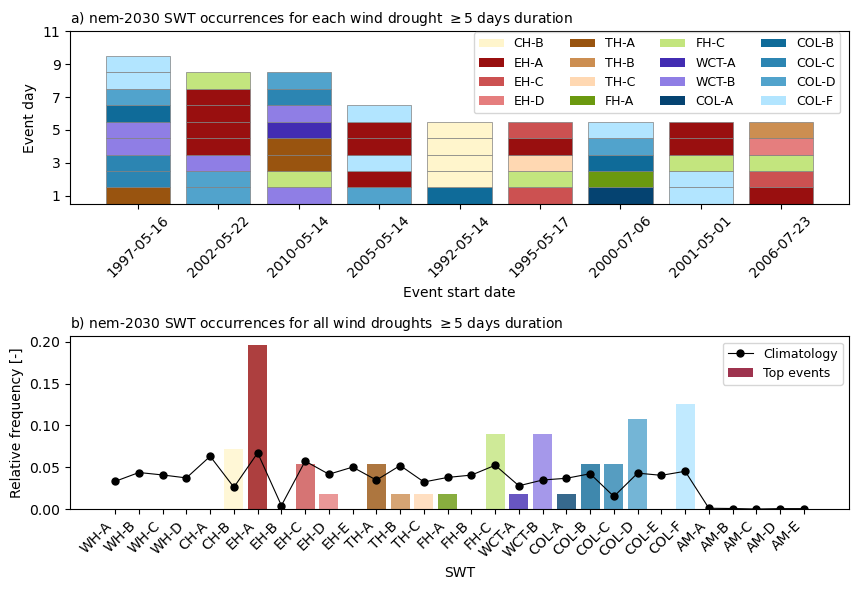

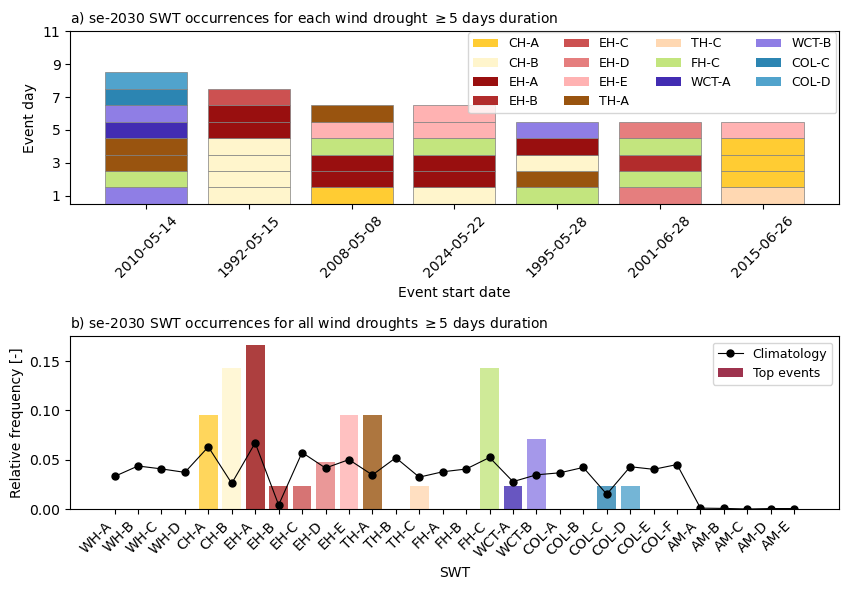

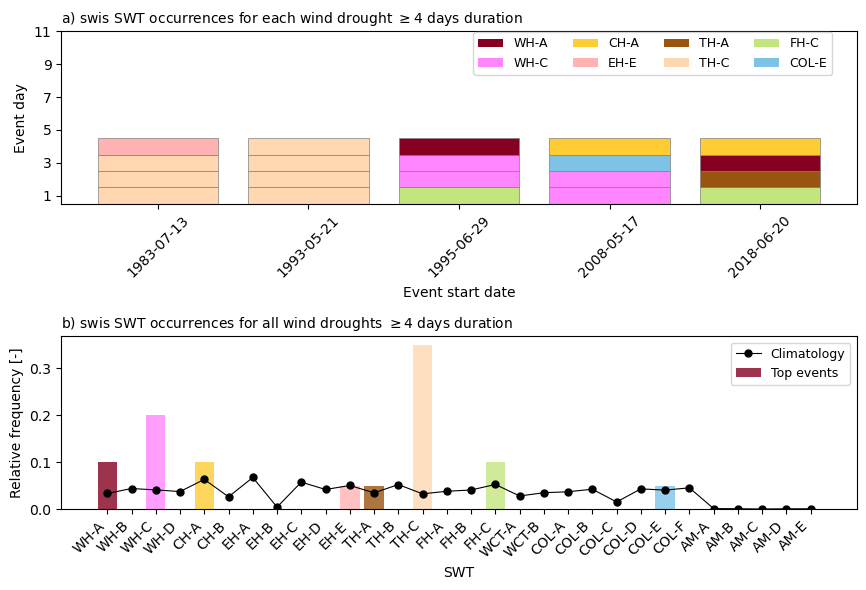

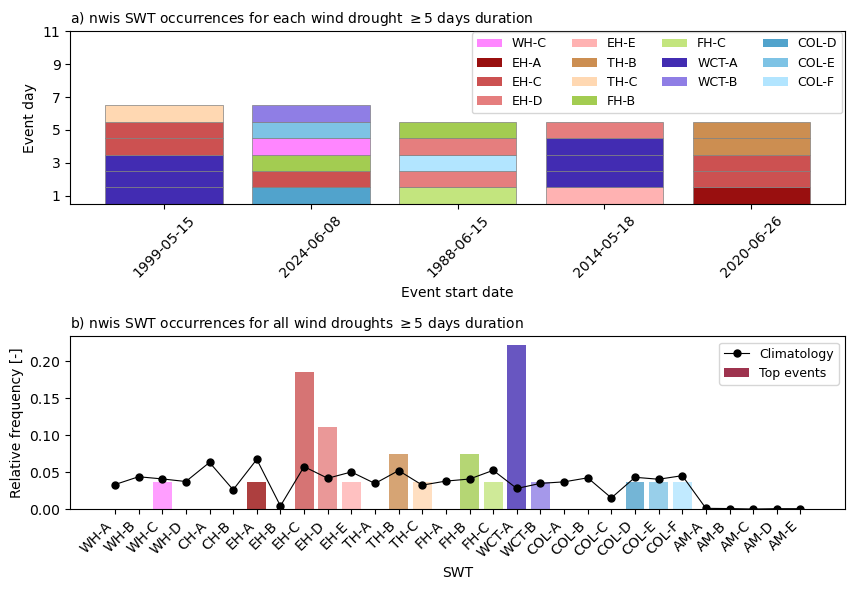

In [114]:
for r in regions:
    fig, axes = plt.subplots(2, 1, figsize=(9, 6))
    
    ax = axes[0]
    plot_swt_by_event(ax, r, drought_type='top')
    
    ax = axes[1]
    plot_swt_hist(ax, swt_distributions, r, show_other=False)
    
    plt.tight_layout()

    plt.savefig("figures/events_swt_"+r+"_barra.png")

### Gridded data

#### BARRA-R2

In [29]:
barra_diagnostics_path = "/g/data/ng72/dr6273/work/projects/wind_drought/data/BARRA-R2/"

Land fraction (for temperature and radiation)

In [30]:
# sftlf_barra = xr.open_dataset(
#     "/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/fx/sftlf/latest/sftlf_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1.nc",
# )["sftlf"]

In [31]:
# land_barra = sftlf_barra.where(sftlf_barra > 0)

tas

In [32]:
tas_barra = xr.open_zarr(
    barra_diagnostics_path + "tas_dayofyear_anoms_1979-2025.zarr",
    consolidated=False
)["tas"].drop_vars(["height", "dayofyear", "crs"])

rsds

In [33]:
# rsds_barra = xr.open_zarr(
#     barra_diagnostics_path + "rsds_dayofyear_anoms_1979-2025.zarr",
#     consolidated=False
# )["rsds"].drop_vars(["dayofyear", "crs"])

In [34]:
# rsds_barra = rsds_barra.where(land_barra.notnull())

In [35]:
# rsds_barra

MSLP (psl)

In [36]:
psl_barra_path = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/day/psl/latest/'

Cloud cover

In [37]:
clt_barra_path = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/day/clt/latest/'

u and v wind (for plotting direction easily)

In [38]:
uas_barra_path = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/day/uas/latest/'
vas_barra_path = '/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/day/vas/latest/'

Wind speed and direction (sfcWind)

In [39]:
wind_barra = xr.open_zarr(
    barra_diagnostics_path + "wind_sfc_speed_direction_1979-2025.zarr",
    consolidated=False
).drop_vars(["height", "crs"])

In [40]:
wind_speed_barra = wind_barra["wind_speed"]
wind_dir_barra = wind_barra["wind_direction"]

#### ERA5

In [41]:
era_diagnostics_path = "/g/data/ng72/dr6273/work/projects/wind_drought/data/ERA5/"

In [42]:
t850_era = xr.open_zarr(
    era_diagnostics_path + "t850_dayofyear_anoms_1979-2024.zarr",
    consolidated=False
).drop_vars(["dayofyear", "level"])

In [43]:
# Add 1 hour to match BARRA times
t850_era["time"] = t850_era["time"] + pd.Timedelta(hours=1)

In [44]:
uv850_era = xr.open_zarr(
    era_diagnostics_path + "uv850_dayofyear_anoms_1979-2024.zarr",
    consolidated=False
).drop_vars(["level"])

In [45]:
# Add 1 hour to match BARRA times
uv850_era["time"] = uv850_era["time"] + pd.Timedelta(hours=1)

In [46]:
z500_era = xr.open_zarr(
    era_diagnostics_path + "z500_dayofyear_anoms_1979-2024.zarr",
    consolidated=False
).drop_vars(["dayofyear", "level"])

In [47]:
# Add 1 hour to match BARRA times
z500_era["time"] = z500_era["time"] + pd.Timedelta(hours=1)

In [48]:
# Convert to geopotential height
g0 = 9.80665 # m / s^2
z500_era = z500_era / g0

In [49]:
u300_era = xr.open_zarr(
    era_diagnostics_path + "u300_dayofyear_anoms_1979-2024.zarr",
    consolidated=False
).drop_vars(["dayofyear", "level"])

In [50]:
# Add 1 hour to match BARRA times
u300_era["time"] = u300_era["time"] + pd.Timedelta(hours=1)

### Composite plots

In [51]:
def plot_ts(ax, da, thresh):
    """ Plot wind drought event time series """
    da.plot(marker='o')
    ax.axhline(thresh, c="k")
    ax.fill_between(x=da.time, y1=da, y2=thresh, where=da<thresh, interpolate=True, alpha=0.5)

In [52]:
def event_slice(da, event_start, event_duration, days_before, days_after):
    """ Return da around event """
    time_slice = pd.date_range(
        pd.to_datetime(event_start) - pd.DateOffset(days=days_before),
        pd.to_datetime(event_start) + pd.DateOffset(days=event_duration + days_after - 1)
    ) + pd.Timedelta(hours=12)
    return da.sel(time=time_slice)

In [53]:
def barra_var_for_month(var_name, var_path, year, month):
    """
    BARRA-R2 data for a given month

    var_name: str, name of variable
    var_path: str, path to variable
    year: str, year to open
    month: str, month to open
    """
    def _barraR2_preprocess(ds):
        """ Return smaller region """
        ds = ds.sel(
            lon=slice(REGION[0], REGION[1]),
            lat=slice(REGION[3], REGION[2])
        )
        return ds
    REGION = fn.get_Aus_boundary()
        
    var_fname = var_name + '_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1_day_'
    return xr.open_mfdataset(
        var_path + var_fname + year + month + '-' + year + month + '.nc',
        preprocess=_barraR2_preprocess
    )[var_name]

In [54]:
def barra_var_for_event(event_start, event_duration, days_before, days_after, var_name, var_path):
    """
    BARRA-R2 data during an event

    event_start: str, start day of event in format yyyy-mm-dd
    event_duration: int or float, duration of event
    days_before: int, days before event
    days_after: int, days after event
    var_name: str, name of variable
    var_path: str, path to variable
    """
    year, month, day = event_start.split('-')
    next_month = (int(month)+1) % 12
    next_month = f"{next_month:02}"

    # Data for start month, and next month, in case event lasts into next month
    var_month = barra_var_for_month(var_name, var_path, year, month)
    var_month_next = barra_var_for_month(var_name, var_path, year, next_month)
    var_month = xr.concat([var_month, var_month_next], dim="time")

    time_slice = pd.date_range(
        pd.to_datetime(event_start) - pd.DateOffset(days=days_before),
        pd.to_datetime(event_start) + pd.DateOffset(days=event_duration + days_after - 1)
    ) + pd.Timedelta(hours=12)

    return var_month.sel(time=time_slice)

In [55]:
def write_sfc_plot_data(event_df, region, event_id, days_before=0, days_after=2):
    """Return array of event data to plot"""
    start = event_df.iloc[event_id].name.strftime("%Y-%m-%d")
    duration, end = event_df[['WDDx', 'end_date']].iloc[event_id]

    # # sfcWind speed and direction
    # wind_speed = event_slice(wind_speed_barra, start, duration, days_before, days_after)
    # wind_direction = event_slice(wind_dir_barra, start, duration, days_before, days_after)

    # surface u and v wind
    uas = barra_var_for_event(start, duration, days_before, days_after, 'uas', uas_barra_path)
    vas = barra_var_for_event(start, duration, days_before, days_after, 'vas', vas_barra_path)

    # MSLP
    mslp = barra_var_for_event(start, duration, days_before, days_after, 'psl', psl_barra_path)

    # temperature anomalies
    tas = event_slice(tas_barra, start, duration, days_before, days_after)

    # cloud cover
    clt = barra_var_for_event(start, duration, days_before, days_after, 'clt', clt_barra_path)

    # ds = xr.merge([wind_speed, wind_direction, mslp, tas, clt], compat="no_conflicts")
    ds = xr.merge([uas, vas, mslp, tas, clt], compat="no_conflicts")

    write_path = "/g/data/ng72/dr6273/work/projects/wind_drought/plotting/wind_drought_composites/sfc_barra/"
    ds.to_netcdf(write_path + "wddx_" + region + "_" + str(event_id) + "_" + start + ".nc")

In [56]:
def write_pl_plot_data(event_df, region, event_id, days_before=0, days_after=2):
    """Return array of event data to plot"""
    start = event_df.iloc[event_id].name.strftime("%Y-%m-%d")
    duration, end = event_df[['WDDx', 'end_date']].iloc[event_id]

    # 850 hPa temperature anomalies
    t850 = event_slice(t850_era["t_anom"], start, duration, days_before, days_after)
    t850.name = 't850_anom'
    
    # 850 hPa u and v anomalies
    u850 = event_slice(uv850_era["u"], start, duration, days_before, days_after)
    u850.name = 'u850'
    v850 = event_slice(uv850_era["v"], start, duration, days_before, days_after)
    v850.name = 'v850'

    # 500 hPa geopotential height
    z500 = event_slice(z500_era["z"], start, duration, days_before, days_after)
    z500.name = 'z500'
    z500_anom = event_slice(z500_era["z_anom"], start, duration, days_before, days_after)
    z500_anom.name = 'z500_anom'

    # 300 hPa u
    u300 = event_slice(u300_era["u"], start, duration, days_before, days_after)
    u300.name = 'u300'

    ds = xr.merge([t850, u850, v850, z500, z500_anom, u300], compat="no_conflicts")

    write_path = "/g/data/ng72/dr6273/work/projects/wind_drought/plotting/wind_drought_composites/pl_era/"
    ds.to_netcdf(write_path + "wddx_" + region + "_" + str(event_id) + "_" + start + ".nc")

In [57]:
droughts_dfs['nem-2030'].sort_values("WDDx", ascending=False).head()

,WDDx,end_date
start_date,,
1997-05-16,9,1997-05-24
2002-05-22,8,2002-05-29
2010-05-14,8,2010-05-21
2005-05-14,6,2005-05-19
1992-05-14,5,1992-05-18


In [55]:
# # For top droughts
# for region in list(droughts_subset.keys()):
#     for event_id in range(3):
#         write_sfc_plot_data(droughts_subset[region]["top"], region, event_id)
#         write_pl_plot_data(droughts_subset[region]["top"], region, event_id)

In [58]:
# # For all WDDx
# for region in list(droughts_dfs.keys())[:]:
#     print(region)
    
#     # df = droughts_dfs[region].sort_values("WDDx", ascending=False)
#     df = (
#         droughts_dfs[region]
#         .rename_axis("start_date")
#         .reset_index()
#         .sort_values(
#             ["WDDx", "start_date"],
#             ascending=[False, True],
#         )
#         .set_index("start_date")
#     )
    
#     for event_id in range(len(droughts_dfs[region]))[:]:
#         # print(df.iloc[event_id].name)
#         year = df.iloc[event_id].name.year
#         print(year)
#         if year >= 2025:
#             pass
#         else:
#             write_sfc_plot_data(df, region, event_id)
#             write_pl_plot_data(df, region, event_id)

In [264]:
def add_midpoints(levels, exclude_zero=False):
    levels = np.asarray(levels, dtype=float)

    new_levels = []

    for left, right in zip(levels[:-1], levels[1:]):
        new_levels.extend([left, (left + right) / 2])

    new_levels.append(levels[-1])

    new_levels = np.asarray(new_levels)

    if exclude_zero:
        new_levels = new_levels[new_levels != 0]

    return new_levels

In [265]:
add_midpoints(np.arange(4500, 6500, 200))

array([4500., 4600., 4700., 4800., 4900., 5000., 5100., 5200., 5300.,
       5400., 5500., 5600., 5700., 5800., 5900., 6000., 6100., 6200.,
       6300.])

In [266]:
def plot_sfc_barra(
    ax, da, tas_levels=[-6, -4, -2, 2, 4, 6], title="", add_quiver_key=False, composite=False
):
    """ Plot BARRA wind speed and direction, temperature anomalies and cloud cover """
    lats = da.lat.values
    lons = da.lon.values
    projection = ccrs.PlateCarree()

    # 2-m temperature anomalies
    if composite:
        tas_levels = add_midpoints(tas_levels)
        tas_levels = tas_levels[tas_levels != 0]
    t = da["tas"].plot.contourf(ax=ax, levels=tas_levels, zorder=0, add_colorbar=False)

    # Cloud cover
    cloud_levels = [75, 100]
    ax.contourf(
        lons,
        lats,
        da["clt"].rolling(lat=10, lon=10, center=True).mean().values,
        levels=cloud_levels,
        colors="#8C8C8C",
        alpha=0.35,
        transform=projection,
        zorder=2,
    )

    # Wind
    u_val = da["uas"].values
    v_val = da["vas"].values
    step = 20
    
    quiv = ax.quiver(
        lons[::step],
        lats[::step],
        u_val[::step, ::step],
        v_val[::step, ::step],
        transform=projection,
        color="k",
        scale=130,       # smaller value gives larger arrows
        width=0.006,
        zorder=5,
    )

    if add_quiver_key:
        ax.quiverkey(
            quiv,
            X=0.08,
            Y=-0.08,
            U=10,
            label="10 m s$^{-1}$",
            labelpos="E",
            coordinates="axes",
            fontproperties={"size": 8},
        )

    # MSLP
    (da["psl"] / 100).plot.contour(
        ax=ax,
        levels=np.arange(960, 1041, 5),
        colors="#303030",
        linewidths=1.2,
        # alpha=0.8,
        add_colorbar=False,
        zorder=3
    )

    ax.set_title(title, loc="left", fontsize=8)
    ax.coastlines(linewidth=0.6, zorder=4)
    # ax.set_extent([90, 180, 0, -49])
    ax.set_xlabel("")
    ax.set_ylabel("")

    return t

In [275]:
def plot_pl_era(
    ax, da, t850_levels=[-6, -4, -2, 2, 4, 6], title="", add_quiver_key=False, composite=False
):
    """ Plot ERA pressure-level diagnostics."""
    lats = da.lat.values
    lons = da.lon.values
    projection = ccrs.PlateCarree()

    # 850hPa temperature anomalies
    if composite:
        t850_levels = add_midpoints(t850_levels)
        t850_levels = t850_levels[t850_levels != 0]
    da["t850_anom"].plot.contourf(ax=ax, levels=t850_levels, zorder=0, add_colorbar=False)

    # Wind
    u_val = da["u850"].values
    v_val = da["v850"].values
    step = 5
    
    quiv = ax.quiver(
        lons[::step],
        lats[::step],
        u_val[::step, ::step],
        v_val[::step, ::step],
        transform=projection,
        color="k",
        scale=230,       # smaller value gives larger arrows
        width=0.006,
        zorder=5,
    )

    if add_quiver_key:
        qk = ax.quiverkey(
            quiv,
            X=0.08,
            Y=-0.08,
            U=20,
            label="20 m s$^{-1}$",
            labelpos="E",
            coordinates="axes",
            color="k",
            fontproperties={"size": 8},
        )

    # z500
    z500_levels = np.arange(4500, 6500, 200)

    da["z500"].plot.contour(
        ax=ax,
        levels=z500_levels,
        colors="#303030",
        linewidths=1.2,
        # alpha=0.8,
        add_colorbar=False,
        zorder=3
    )

    # z500 anomalies
    z500_anom_levels = np.arange(-800, 801, 100)
    if composite:
        z500_anom_levels = add_midpoints(z500_anom_levels)
    z500_anom_levels = z500_anom_levels[z500_anom_levels != 0]
    
    da["z500_anom"].plot.contour(
        ax=ax,
        levels=z500_anom_levels,
        colors="tab:pink",
        linewidths=1.6,
        # alpha=0.8,
        add_colorbar=False,
        zorder=3
    )

    # u300
    da["u300"].plot.contour(
        ax=ax,
        levels=[30, 40, 50, 60, 70],
        colors="tab:gray",
        linewidths=[0.8, 1.2, 1.6, 2.0, 2.0],
        transform=ccrs.PlateCarree(),
        add_colorbar=False,
    )

    ax.set_title(title, loc="left", fontsize=8)
    ax.coastlines(linewidth=0.6, zorder=4)
    ax.set_extent([90, 170, 0, -49])
    ax.set_xlabel("")
    ax.set_ylabel("")

In [234]:
def plot_event_maps(event_name, da_sfc, da_pl, days_before=0, days_after=2):
    """Plot composite maps followed by maps of the event sequence."""

    n_times = len(da_sfc.time)
    n_event_times = n_times - days_before - days_after
    times_per_row = 6

    # Composite excluding the final two days
    da_sfc_composite = da_sfc.isel(time=range(days_before, n_event_times - days_after)).mean("time")
    da_pl_composite = da_pl.isel(time=range(days_before, n_event_times - days_after)).mean("time")

    # One extra slot for the composite
    n_slots = n_times + 1 #n_event_times + 1
    n_time_rows = math.ceil(n_slots / times_per_row)

    fig, axes = plt.subplots(
        2 * n_time_rows,
        times_per_row,
        figsize=(18, 4.5 * n_time_rows),
        subplot_kw={"projection": ccrs.PlateCarree()},
        squeeze=False,
    )

    # Plot composite in slot 0
    p = plot_sfc_barra(
        axes[0, 0],
        da_sfc_composite,
        add_quiver_key=True
    )

    plot_pl_era(
        axes[1, 0],
        da_pl_composite,
        add_quiver_key=True
    )
    
    axes[0, 0].set_title("", loc="center")
    axes[0, 0].set_title("Composite mean", fontsize=8, loc="left")
    
    axes[1, 0].set_title("", loc="center")

    # Plot individual event days in slots 1 onward
    break_time = 1
    for time in range(n_times):
        slot = time + 1

        time_row = slot // times_per_row
        col = slot % times_per_row

        sfc_row = 2 * time_row
        pl_row = sfc_row + 1

        plot_sfc_barra(
            axes[sfc_row, col],
            da_sfc.isel(time=time),
        )

        plot_pl_era(
            axes[pl_row, col],
            da_pl.isel(time=time),
        )

        axes[sfc_row, col].set_title("", loc="center")
        
        if slot < n_times - 1:
            axes[sfc_row, col].set_title("Day " + str(time + 1), fontsize=8, loc="left")
            axes[pl_row, col].set_title("", loc="center")
        else:
            axes[sfc_row, col].set_title("Break day " + str(break_time), fontsize=8, loc="left")
            break_time += 1
            
        axes[pl_row, col].set_title("", loc="center")

    # Hide unused axes
    for slot in range(n_slots, n_time_rows * times_per_row):
        time_row = slot // times_per_row
        col = slot % times_per_row

        axes[2 * time_row, col].set_visible(False)
        axes[2 * time_row + 1, col].set_visible(False)

    # Row labels
    for time_row in range(n_time_rows):
        sfc_ax = axes[2 * time_row, 0]
        pl_ax = axes[2 * time_row + 1, 0]

        sfc_pos = sfc_ax.get_position()
        pl_pos = pl_ax.get_position()

        fig.text(
            sfc_pos.x0 - 0.01,
            (sfc_pos.y0 + sfc_pos.y1) / 2,
            "Surface",
            rotation=90,
            va="center",
            ha="center",
            fontsize=8,
        )

        fig.text(
            pl_pos.x0 - 0.01,
            (pl_pos.y0 + pl_pos.y1) / 2,
            "Troposphere",
            rotation=90,
            va="center",
            ha="center",
            fontsize=8,
        )

    # Shared colourbar
    cax = fig.add_axes([0.92, 0.35, 0.015, 0.3])

    cbar = fig.colorbar(
        p,
        cax=cax,
        orientation="vertical",
    )

    cbar.set_label("Temperature anomaly [K]")

    plt.savefig("figures/dynamics_"+region+"_"+event_name+".png", dpi=300)
    plt.close(fig)

    return fig, axes

In [235]:
PLOT_DATA_PATH = "/g/data/ng72/dr6273/work/projects/wind_drought/plotting/wind_drought_composites/"

In [251]:
droughts_subset_sorted = (
    droughts_subset[region]["top"]
    .rename_axis("start_date")
    .reset_index()
    .sort_values(
        ["WDDx", "start_date"],
        ascending=[False, True],
    )
    .set_index("start_date")
)

In [255]:
droughts_subset_sorted

,WDDx,end_date
start_date,,
1999-05-15,6,1999-05-20
2024-06-08,6,2024-06-13
1988-06-15,5,1988-06-19
2014-05-18,5,2014-05-22
2020-06-26,5,2020-06-30


In [256]:
# Top droughts - each event
for region in list(droughts_subset.keys())[3:]:

    droughts_subset_sorted = (
        droughts_subset[region]["top"]
        .rename_axis("start_date")
        .reset_index()
        .sort_values(
            ["WDDx", "start_date"],
            ascending=[False, True],
        )
        .set_index("start_date")
    )
    
    for event_id in range(3)[:]:
        
        event_name = droughts_subset_sorted.iloc[event_id].name.strftime("%Y-%m-%d")
        print(event_name)
        
        da_sfc = xr.open_dataset(PLOT_DATA_PATH + "/sfc_barra/wddx_" + region + "_" + str(event_id) + "_" + event_name + ".nc")
        da_pl = xr.open_dataset(PLOT_DATA_PATH + "/pl_era/wddx_" + region + "_" + str(event_id) + "_" + event_name + ".nc")

        event_name = event_name + "_" + str(event_id)
        plot_event_maps(event_name, da_sfc, da_pl)

1999-05-15
2024-06-08
1988-06-15


In [196]:
from pathlib import Path

In [197]:
def get_composite(region, droughts, duration):
    """ Return composite array for droughts of a given duration"""
    # Start dates of events with this duration
    starts = droughts[droughts == duration].index

    sfc_events = []
    pl_events = []

    for start in starts:
        start_str = start.strftime("%Y-%m-%d")
        directory = Path(PLOT_DATA_PATH + "pl_era/")
        file = [path.name for path in directory.glob(f"*{region}*{start_str}*.nc")][0]

        da_sfc = xr.open_dataset(PLOT_DATA_PATH + "/sfc_barra/" + file)
        da_pl = xr.open_dataset(PLOT_DATA_PATH + "/pl_era/" + file)

        end = start + pd.Timedelta(days=int(duration))
        
        sfc_events.append(
            da_sfc.sel(time=slice(start, end))
        )

        pl_events.append(
            da_pl.sel(time=slice(start, end))
        )

    # Combine all event days into one time dimension
    da_sfc_length = xr.concat(sfc_events, dim="time")
    da_pl_length = xr.concat(pl_events, dim="time")
    n = len(da_sfc_length.time.values)

    # Calculate composite over all days and all events
    da_sfc_composite = da_sfc_length.mean("time")
    da_pl_composite = da_pl_length.mean("time")

    return (da_sfc_composite, da_pl_composite, n)

In [277]:
def plot_composites(events_df):
    """Plot composite maps as a function of event length."""

    durations = sorted(droughts.unique(), reverse=True)

    durations_per_row = 4
    n_duration_rows = math.ceil(len(durations) / durations_per_row)

    fig, axes = plt.subplots(
        2 * n_duration_rows,
        durations_per_row,
        figsize=(18, 6 * n_duration_rows),
        subplot_kw={"projection": ccrs.PlateCarree()},
        squeeze=False,
    )

    for i, duration in enumerate(durations):
    
        duration_row = i // durations_per_row
        col = i % durations_per_row
    
        sfc_row = 2 * duration_row
        pl_row = sfc_row + 1
    
        da_sfc_composite, da_pl_composite, n = get_composite(
            region,
            droughts,
            duration,
        )
    
        p = plot_sfc_barra(
            axes[sfc_row, col],
            da_sfc_composite,
            # composite=True
        )
    
        plot_pl_era(
            axes[pl_row, col],
            da_pl_composite,
            # composite=True
        )

        axes[sfc_row, col].set_title(
            f"{duration}-day events"+r" ($n=$"+str(n)+")",
            fontsize=8,
            loc="left",
        )
    
        # Remove automatic centre titles
        axes[sfc_row, col].set_title("", loc="center")
        axes[pl_row, col].set_title("", loc="center")
    
    # Hide unused axes
    for i in range(len(durations), n_duration_rows * durations_per_row):

        duration_row = i // durations_per_row
        col = i % durations_per_row
    
        axes[2 * duration_row, col].set_visible(False)
        axes[2 * duration_row + 1, col].set_visible(False)

    # Row labels
    for duration_row in range(n_duration_rows):
    
        sfc_ax = axes[2 * duration_row, 0]
        pl_ax = axes[2 * duration_row + 1, 0]
    
        sfc_pos = sfc_ax.get_position()
        pl_pos = pl_ax.get_position()
    
        fig.text(
            sfc_pos.x0 - 0.01,
            (sfc_pos.y0 + sfc_pos.y1) / 2,
            "Surface",
            rotation=90,
            va="center",
            ha="center",
            fontsize=8,
        )
    
        fig.text(
            pl_pos.x0 - 0.01,
            (pl_pos.y0 + pl_pos.y1) / 2,
            "Troposphere",
            rotation=90,
            va="center",
            ha="center",
            fontsize=8,
        )

    # Shared colourbar
    cax = fig.add_axes([0.92, 0.35, 0.015, 0.3])

    cbar = fig.colorbar(
        p,
        cax=cax,
        orientation="vertical",
    )

    cbar.set_label("Temperature anomaly [K]")

    # plt.savefig("figures/dynamics_"+region+"_"+event_name+".png", dpi=300)
    # plt.close(fig)

    return fig, axes

In [278]:
region = "nem-2030"
droughts = droughts_dfs[region]["WDDx"]

In [279]:
# Necessary until ERA5 data is updated to 2025
droughts = droughts[droughts.index.year < 2025]

(<Figure size 1800x1200 with 17 Axes>,
 array([[<GeoAxes: title={'left': '9-day events ($n=$9)'}>,
         <GeoAxes: title={'left': '8-day events ($n=$16)'}>,
         <GeoAxes: title={'left': '6-day events ($n=$6)'}>,
         <GeoAxes: title={'left': '5-day events ($n=$25)'}>],
        [<GeoAxes: >, <GeoAxes: >, <GeoAxes: >, <GeoAxes: >],
        [<GeoAxes: title={'left': '4-day events ($n=$28)'}>,
         <GeoAxes: title={'left': '3-day events ($n=$36)'}>,
         <GeoAxes: title={'left': '2-day events ($n=$26)'}>,
         <GeoAxes: title={'left': '1-day events ($n=$4)'}>],
        [<GeoAxes: >, <GeoAxes: >, <GeoAxes: >, <GeoAxes: >]], dtype=object))

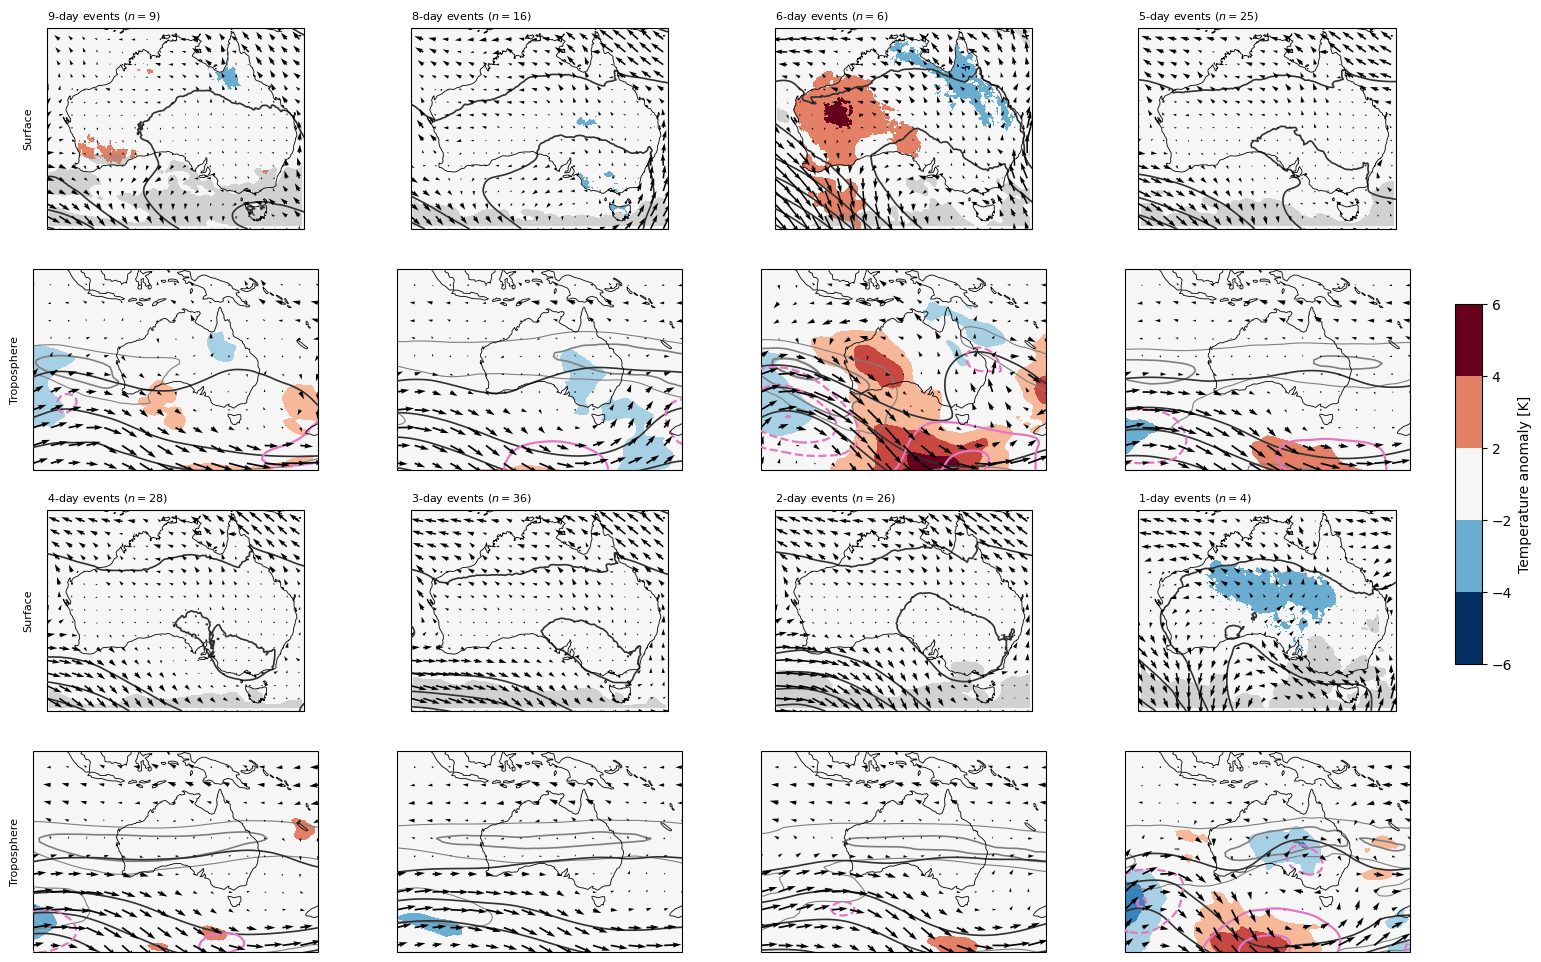

In [280]:
plot_composites(droughts)

In [89]:
import xclim as xc

def calc_wdd(timeseries, pctl10):
    """Calculate wind drought duration (WDDx) for a single timeseries"""

    calm_days = timeseries < pctl10
    drought_events = xc.indices.run_length.find_events(calm_days, window=1)
    drought_events = drought_events.assign_coords(
        time=('event', drought_events['event_start'].data)
    ).drop_vars('event_start')
    drought_events = drought_events.swap_dims({'event': 'time'}).dropna('time')
    # wddx_da = drought_events['event_length'].resample(time='1YS').max()
    # wddx_times = drought_events['event_length'].resample(time='1YS').map(xr.DataArray.idxmax, dim='time', keep_attrs=True)
    # wddx_da['time'] = wddx_times
    # wddx_ds = wddx_da.to_dataset()

    return drought_events

In [90]:
# wddx_obs = {}
# for r, da in obs_dict.items():
#     pctl10 = np.percentile(da['sfcWind'], 10)
#     print(pctl10)
#     wddx_obs[r] = utils.calc_wddx_obs(da, pctl10)

In [95]:
wdd = calc_wdd(obs_dict['nem-2030']['sfcWind'], np.percentile(obs_dict['nem-2030']['sfcWind'], 10)).event_length

(array([28., 13.,  0.,  5.,  1.,  0.,  0.,  2.,  1.]),
 array([3.        , 3.66666667, 4.33333333, 5.        , 5.66666667,
        6.33333333, 7.        , 7.66666667, 8.33333333, 9.        ]),
 <BarContainer object of 9 artists>)

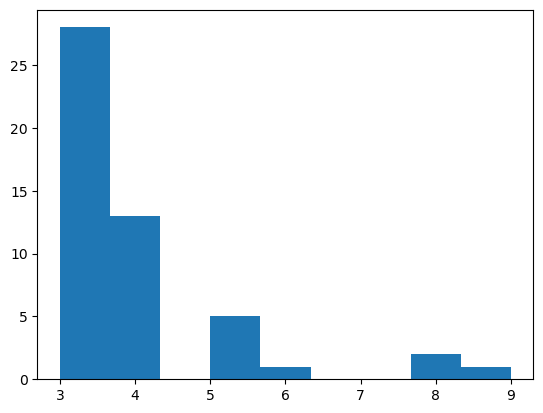

In [98]:
plt.hist(wdd.where(wdd > 2), bins=9)